In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

In [2]:
p_simPath = "/home/oliviag/ngspice-skywater-sims/pfet_mod/"
n_simPath = "/home/oliviag/ngspice-skywater-sims/nfet_mod/"

measPath = "/home/oliviag/Skywater-130nm-77K-Cryogenic-Models/cryo_data/"
simVG = [
    "idVg_vd_0p010.txt",
    "idVg_vd_0p370.txt",
    "idVg_vd_1p480.txt",
    "idVg_vd_0p740.txt",
    "idVg_vd_1p110.txt",
    "idVg_vd_1p850.txt"
]
simVD = [
    "idVd_vg_0p370.txt",
    "idVd_vg_0p740.txt",
    "idVd_vg_1p480.txt",
    "idVd_vg_1p110.txt",
    "idVd_vg_1p850.txt"
]

In [3]:
#pmos comparison data
p_measVG = [
    "idvg_Vd-0p01.csv",
    "idvg_Vd-0p37.csv",
    "idvg_Vd-1p48.csv",
    "idvg_Vd-0p74.csv",
    "idvg_Vd-1p11.csv",
    "idvg_Vd-1p85.csv"
]
p_measVD = [
    "idvd_Vg-0p37.csv",
    "idvd_Vg-0p74.csv",
    "idvd_Vg-1p48.csv",
    "idvd_Vg-1p11.csv",
    "idvd_Vg-1p85.csv"
]
p_sim_devices = [
    "l_0p35_w_1p6",
    "l_0p50_w_0p42",
    "l_2p0_w_5p0",
    "l_8p0_w_0p84",
    "l_8p0_w_5p0",
    "l_0p35_w_0p55",
    "l_0p35_w_5p0",
    "l_0p50_w_0p64",
    "l_4p0_w_7p0",
    "l_8p0_w_1p6"
]
p_meas_devices = [
    'pmos_FET_len_0.35_wid_1.6',
    'pmos_FET_len_0p5_wid_0p42',
    'pmos_FET_len_2_wid_5',
    'pmos_FET_len_8_wid_0p84',
    'pmos_FET_len_8_wid_5',
    'pmos_FET_len_0p35_wid_0p55',
    'pmos_FET_len_0p35_wid_5',
    'pmos_FET_len_0p5_wid_0p64',   
    'pmos_FET_len_4_wid_7', 
    'pmos_FET_len_8_wid_1p6'
    
]

In [4]:
#nmos comparison data
n_measVG = [
    "idvg_Vd0p37.csv",
    "idvg_Vd1p48.csv",
    "idvg_Vd0p74.csv",
    "idvg_Vd1p11.csv",
    "idvg_Vd0p01.csv",
    "idvg_Vd1p85.csv"
]
n_measVD = [
    "idvd_Vg0p37.csv",
    "idvd_Vg1p48.csv",
    "idvd_Vg0p74.csv",
    "idvd_Vg1p11.csv",
    "idvd_Vg1p85.csv"
]

n_sim_devices = [
    "l_0p15_w_1p6",
    "l_0p19_w_7p0",
    "l_0p25_w_1p6",
    "l_1p0_w_1p6",
    "l_1p0_w_3p0",
    "l_8p0_w_1p6",
    "l_20p0_w_0p64",
    "l_100p0_w_100p0"
]

n_meas_devices = [
    'nmos_FET_len_0p15_wid_1p6', 
    'nmos_FET_len_0p19_wid_7',
    'nmos_FET_len_0p25_wid_1p6', 
    'nmos_FET_len_1_wid_1p6', 
    'nmos_FET_len_1_wid_3', 
    'nmos_FET_len_8_wid_1.6', 
    'nmos_FET_len_20_wid_0p64', 
    'nmos_FET_len_100_wid_100'
]

In [13]:
#device configuration
desired_doping = 'n'
desired_device = 2

sim_dev_path = os.path.join(globals()[f'{desired_doping}_simPath'], globals()[f'{desired_doping}_sim_devices'][desired_device])
meas_dev_path = os.path.join(measPath, globals()[f'{desired_doping}_meas_devices'][desired_device])
dev_s = globals()[f'{desired_doping}_sim_devices'][desired_device]

['idvg_Vd0p37.csv', 'idvg_Vd1p48.csv', 'idvg_Vd0p74.csv', 'idvg_Vd1p11.csv', 'idvg_Vd0p01.csv', 'idvg_Vd1p85.csv']


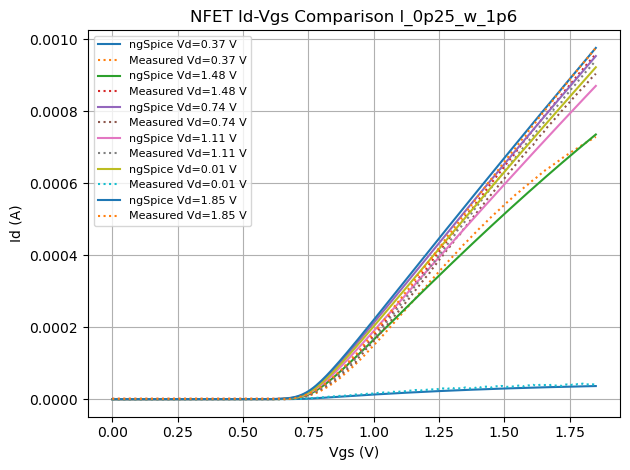

In [7]:
#VGS plots
measVG = globals()[f'{desired_doping}_measVG']

for simFile, measFile in zip(simVG, measVG):
    p_s = os.path.join(sim_dev_path, "vg_sweep/", simFile)
    p_m = os.path.join(meas_dev_path, measFile)
    simData = np.loadtxt(p_s)
    measData =np.loadtxt(p_m, delimiter=',', skiprows=1)
    vd = np.abs(measData[0,0])
    plt.plot(
        np.abs(simData[:, 0]),
        np.abs(simData[:, 3]),
        label=f"ngSpice Vd={vd} V"
    )
    plt.plot(
        np.abs(measData[:,1]),   
        np.abs(measData[:,2]),   
        ':',
        label=f"Measured Vd={vd} V"
    )
plt.xlabel("Vgs (V)")
plt.ylabel("Id (A)")
plt.title(f"NFET Id-Vgs Comparison {dev_s}")
plt.grid(True, which="both")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


In [12]:
outfile = f"VGS_plots/{despired_doping}_{dev_s}_compare.png"
plt.savefig(
    outfile,
    bbox_inches="tight"
)
print(f"Saved {outfile}")
plt.close()

Saved VGS_plots/l_0p25_w_1p6_compare.png


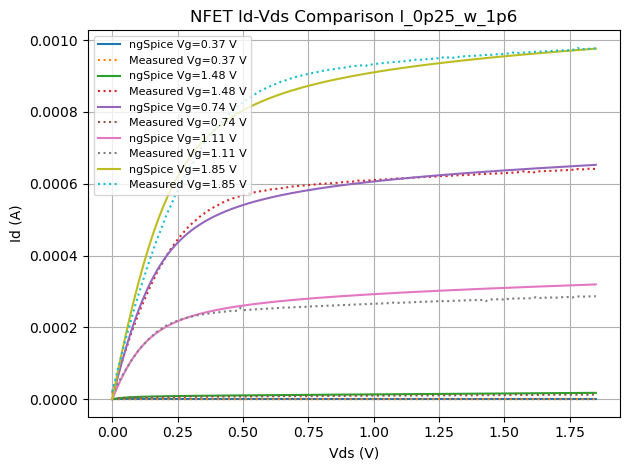

In [14]:
#VDS plots
measVD = globals()[f'{desired_doping}_measVD']

for simFile, measFile in zip(simVD, measVD):
    p_s = os.path.join(sim_dev_path, "vd_sweep/", simFile)
    p_m = os.path.join(meas_dev_path, measFile)
    simData = np.loadtxt(p_s)
    measData =np.loadtxt(p_m, delimiter=',', skiprows=1)
    vg = np.abs(measData[0,1])
    plt.plot(
        np.abs(simData[:, 0]),
        np.abs(simData[:, 3]),
        label=f"ngSpice Vg={vg} V"
    )
    plt.plot(
        np.abs(measData[:,0]),   
        np.abs(measData[:,2]),   
        ':',
        label=f"Measured Vg={vg} V"
    )

plt.xlabel("Vds (V)")
plt.ylabel("Id (A)")
plt.title(f"NFET Id-Vds Comparison {dev_s}")
plt.grid(True, which="both")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
outfile = f"VDS_plots/{despired_doping}_{dev_s}_compare.png"
plt.savefig(
    outfile,
    bbox_inches="tight"
)
print(f"Saved {outfile}")
plt.close()

Saved VDS_plots/l_0p25_w_1p6_compare.png


In [10]:
#plot all
'''plt.figure(figsize=(8, 6))

for dev_s, dev_m in zip(sim_devices, meas_devices):
    pSim = os.path.join(simPath, dev_s)
    pMeas = os.path.join(measPath, dev_m)
    for simFile, measFile in zip(simVG, measVG):
        p_s = os.path.join(pSim, "vg_sweep/", simFile)
        p_m = os.path.join(pMeas, measFile)
        simData = np.loadtxt(p_s)
        measData =np.loadtxt(p_m, delimiter=',', skiprows=1)
        vd = np.abs(measData[0,0])
        plt.plot(
            np.abs(simData[:, 0]),
            np.abs(simData[:, 3]),
            label=f"ngSpice Vd={vd} V"
        )
        plt.plot(
            np.abs(measData[:,1]),   
            np.abs(measData[:,2]),   
            ':',
            label=f"Measured Vd={vd} V"
        )

    plt.xlabel("Vgs (V)")
    plt.ylabel("Id (A)")
    plt.title(f"NFET Id-Vgs Comparison {dev_s}")
    plt.grid(True, which="both")
    plt.legend(fontsize=8)
    plt.tight_layout()
    outfile = f"nfetVGS_compare_{dev_s}.png"
    plt.savefig(
        outfile,
        dpi=300,
        bbox_inches="tight"
    )
    print(f"Saved {outfile}")
    plt.close()
    #Id-Vds plotting
    for simFile, measFile in zip(simVD, measVD):
        p_s = os.path.join(pSim, "vd_sweep/", simFile)
        p_m = os.path.join(pMeas, measFile)
        simData = np.loadtxt(p_s)
        measData =np.loadtxt(p_m, delimiter=',', skiprows=1)
        vg = np.abs(measData[0,1])
        plt.plot(
            np.abs(simData[:, 0]),
            np.abs(simData[:, 3]),
            label=f"ngSpice Vg={vg} V"
        )
        plt.plot(
            np.abs(measData[:,0]),   
            np.abs(measData[:,2]),   
            ':',
            label=f"Measured Vg={vg} V"
        )

    plt.xlabel("Vds (V)")
    plt.ylabel("Id (A)")
    plt.title(f"NFET Id-Vds Comparison {dev_s}")
    plt.grid(True, which="both")
    plt.legend(fontsize=8)
    plt.tight_layout()
    outfile = f"nfetVDS_compare_{dev_s}.png"
    plt.savefig(
        outfile,
        dpi=300,
        bbox_inches="tight"
    )
    print(f"Saved {outfile}")
    plt.close()'''

NameError: name 'sim_devices' is not defined

<Figure size 800x600 with 0 Axes>